# XGBoost for IPL win probability

This notebook tries a small set of XGBoost settings, picks the best by grouped cross-validation, and checks it against Logistic Regression.


In [10]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("XGBoost is missing. Install it with: python -m pip install xgboost") from exc


In [11]:
DATA_CANDIDATES = [
    Path("data/processed/reduced/Final_data.csv"),
    Path("../data/processed/reduced/Final_data.csv"),
]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Can't find data/processed/reduced/Final_data.csv. Open the repo folder in VS Code.")
PROJECT_ROOT = next(
    (
        p.resolve()
        for p in [Path.cwd(), Path.cwd().parent]
        if (p / ".git").exists()
    ),
    Path.cwd().resolve(),
)

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows across {df['match_id'].nunique():,} matches")
df.head()


Loaded 117,558 rows across 1,063 matches


,match_id,team_batting,team_bowling,current_score,season_id,match_date,city,venue,target_runs,runs_left,CRR,balls_left,RRR,wickets_left,runs_last_30,wickets_last_30,won
0,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,1,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,222,6.0,119,11.193277,10,1.0,0.0,0
1,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,2,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,221,6.0,118,11.237288,10,2.0,0.0,0
2,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,3,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,220,6.0,117,11.282051,10,3.0,0.0,0
3,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,6.0,116,11.327586,10,4.0,0.0,0
4,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,4.8,115,11.426087,10,4.0,0.0,0


## 1. Set up the data

Use seasons through 2024 to develop the model. Hold back 2025 onward for the final time-based check. `match_id` is for grouping only, not a predictor.


In [12]:
FEATURES = ["target_runs", "runs_left", "CRR", "balls_left", "RRR", "wickets_left"]
TARGET = "won"
GROUP = "match_id"

required = FEATURES + [TARGET, GROUP, "season_id"]
assert df[required].notna().all().all(), "Required columns contain missing values."
assert set(df[TARGET].unique()).issubset({0, 1}), "The target should be 0 or 1."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has inconsistent outcome labels."

dev = df.loc[df["season_id"] <= 2024].reset_index(drop=True)
test = df.loc[df["season_id"] >= 2025].reset_index(drop=True)
assert not dev.empty and not test.empty, "Need both development seasons and a 2025+ holdout."
assert set(dev[GROUP]).isdisjoint(set(test[GROUP])), "A match appears in both sets."

X_dev, y_dev, groups_dev = dev[FEATURES], dev[TARGET].astype(int), dev[GROUP]
X_test, y_test = test[FEATURES], test[TARGET].astype(int)
print(f"Development: {len(dev):,} rows | {groups_dev.nunique():,} matches | through 2024")
print(f"Holdout: {len(test):,} rows | {test[GROUP].nunique():,} matches | 2025 onward")
print("Latest holdout date:", test["match_date"].max())


Development: 105,663 rows | 953 matches | through 2024
Holdout: 11,895 rows | 110 matches | 2025 onward
Latest holdout date: 2026-05-01


## 2. Tune a few XGBoost settings

We vary the number of trees, learning rate, and tree depth. The other settings stay fixed so the search does not take too long. Three match-grouped folds are used to pick the settings with the lowest mean validation log loss.

This is a first tuning pass, not a search over every XGBoost parameter. Do not use the later-season results to choose settings.


In [13]:
N_SPLITS = 3
FIXED_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "min_child_weight": 10,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}
PARAM_GRID = list(ParameterGrid({
    "n_estimators": [200, 350],
    "learning_rate": [0.03, 0.05],
    "max_depth": [2, 3],
}))
cv = GroupKFold(n_splits=N_SPLITS)
rows = []

for candidate, params in enumerate(PARAM_GRID, start=1):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev, groups_dev), start=1):
        train_matches = set(groups_dev.iloc[train_idx])
        val_matches = set(groups_dev.iloc[val_idx])
        assert train_matches.isdisjoint(val_matches), "A match leaked across folds."

        model = XGBClassifier(**FIXED_PARAMS, **params)
        model.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
        p_val = model.predict_proba(X_dev.iloc[val_idx])[:, 1]
        y_val = y_dev.iloc[val_idx]
        rows.append({
            "candidate": candidate,
            "fold": fold,
            "log_loss": log_loss(y_val, p_val, labels=[0, 1]),
            "brier": brier_score_loss(y_val, p_val),
            "roc_auc": roc_auc_score(y_val, p_val),
            "accuracy": accuracy_score(y_val, p_val >= 0.5),
        })
    print(f"Finished candidate {candidate}/{len(PARAM_GRID)}")

cv_results = pd.DataFrame(rows)
param_table = pd.DataFrame([
    {"candidate": i, **p} for i, p in enumerate(PARAM_GRID, start=1)
]).set_index("candidate")
cv_summary = cv_results.groupby("candidate").agg(
    log_loss_mean=("log_loss", "mean"),
    log_loss_std=("log_loss", "std"),
    brier_mean=("brier", "mean"),
    roc_auc_mean=("roc_auc", "mean"),
    accuracy_mean=("accuracy", "mean"),
)
cv_summary = param_table.join(cv_summary).sort_values("log_loss_mean")
display(cv_summary.round(4))

best_candidate = int(cv_summary.index[0])
best_params = {**FIXED_PARAMS, **PARAM_GRID[best_candidate - 1]}
print("Selected settings:", {k: best_params[k] for k in PARAM_GRID[0]})


Finished candidate 1/8
Finished candidate 2/8
Finished candidate 3/8
Finished candidate 4/8
Finished candidate 5/8
Finished candidate 6/8
Finished candidate 7/8
Finished candidate 8/8


,learning_rate,max_depth,n_estimators,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean
candidate,,,,,,,,
6,0.05,2,350,0.4465,0.0269,0.1475,0.8706,0.7811
2,0.03,2,350,0.4470,0.0203,0.1475,0.8708,0.7801
5,0.05,2,200,0.4472,0.0186,0.1477,0.8705,0.7790
4,0.03,3,350,0.4487,0.0257,0.1484,0.8692,0.7791
7,0.05,3,200,0.4496,0.0266,0.1487,0.8688,0.7787
3,0.03,3,200,0.4497,0.0191,0.1486,0.8691,0.7774
1,0.03,2,200,0.4524,0.0153,0.1491,0.8687,0.7762
8,0.05,3,350,0.4544,0.0336,0.1501,0.8667,0.7781


Selected settings: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 350}


## 3. Compare with Logistic Regression

Train both models on all development seasons, then score the same later-season matches. This holdout is a check, not a place to pick parameters. The dataset only includes part of the 2026 season.


In [14]:
def score_probabilities(name, y_true, p):
    return {
        "model": name,
        "log_loss": log_loss(y_true, p, labels=[0, 1]),
        "brier": brier_score_loss(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "accuracy": accuracy_score(y_true, p >= 0.5),
    }

xgb_final = XGBClassifier(**best_params)
xgb_final.fit(X_dev, y_dev)
p_xgb = xgb_final.predict_proba(X_test)[:, 1]

logreg = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
logreg.fit(X_dev, y_dev)
p_lr = logreg.predict_proba(X_test)[:, 1]

temporal_results = pd.DataFrame([
    score_probabilities("Logistic Regression", y_test, p_lr),
    score_probabilities("XGBoost", y_test, p_xgb),
]).set_index("model").sort_values("log_loss")
display(temporal_results.round(4))


,log_loss,brier,roc_auc,accuracy
model,,,,
Logistic Regression,0.4244,0.1391,0.9001,0.7935
XGBoost,0.4826,0.1583,0.8791,0.7661


## 4. Check calibration

The dashed line is perfect calibration. Curves closer to it have predicted probabilities that better match the observed win rate.


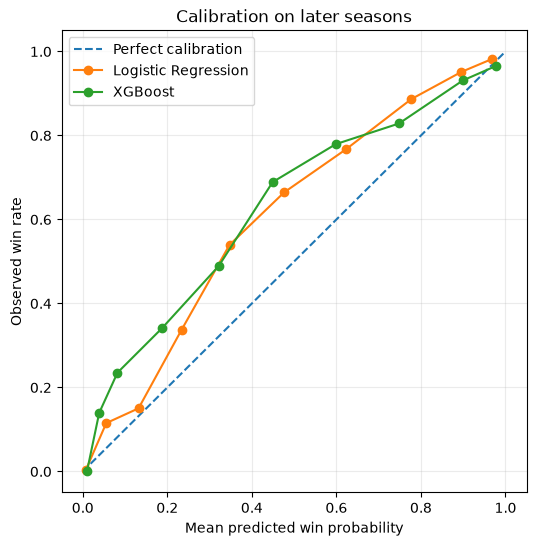

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
for name, probs in [("Logistic Regression", p_lr), ("XGBoost", p_xgb)]:
    observed, predicted = calibration_curve(y_test, probs, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlabel="Mean predicted win probability", ylabel="Observed win rate",
       title="Calibration on later seasons")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 5. Feature importance

These scores show which inputs mattered most to this fitted XGBoost model. They are clues, not proof that a feature causes a win.


,feature,importance
0,RRR,0.6094
1,CRR,0.1049
2,wickets_left,0.0996
3,runs_left,0.0807
4,target_runs,0.0692
5,balls_left,0.0361


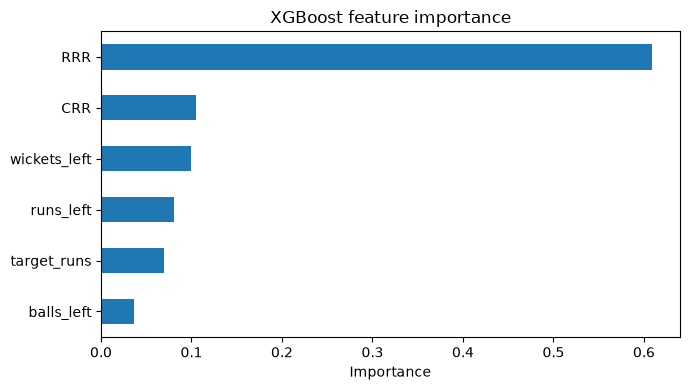

In [16]:
feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": xgb_final.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(feature_importance.round(4))
feature_importance.sort_values("importance").plot(
    kind="barh", x="feature", y="importance", legend=False, figsize=(7, 4),
    title="XGBoost feature importance",
)
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 6. Save the results

These files keep the tuning scores, selected settings, and holdout results for the later model comparison.


In [17]:
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(REPORT_DIR / "xgboost_tuning_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "xgboost_tuning_summary.csv")
temporal_results.to_csv(REPORT_DIR / "xgboost_temporal_holdout.csv")
feature_importance.to_csv(REPORT_DIR / "xgboost_feature_importance.csv", index=False)
with open(REPORT_DIR / "xgboost_best_params.json", "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=2)

print(f"Saved XGBoost reports to {REPORT_DIR}")


Saved XGBoost reports to C:\Users\Lenovo\Documents\IPL ML\reports
